# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest**
neural crest) were scored in 02 against the union control pool. Gate 2 (non-branching): a shared
organized developmental axis with Crest as an inverse/terminal gradient passes as GO; Gate 3 is
NA (no bifurcation).

In [2]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [3]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 59359 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 80/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present


### Gate 2 — module geography on the manifold
(i) global module strengths; (ii) smoothed spatial correlations; (iii) pseudotime gradients;
(iv) which pole the Crest terminus sits at (Crest-arm flag).

In [6]:
print('global module means (all malignant):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('\nsmoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'\nNeural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
# Crest-arm flag: does the Crest terminus co-locate with Gast (flag) or pSom (ideal)?
rcg = np.corrcoef(adata.obs['Crest_sm'], adata.obs['Gast_sm'])[0,1]
rcp = np.corrcoef(adata.obs['Crest_sm'], adata.obs['pSom_sm'])[0,1]
flag = 'FLAG: Crest enriches the Gast side (inversion)' if rcg > rcp else 'Crest enriches the pSom side (ideal)'
print('Crest-arm:', flag, f'(Crest-Gast r={rcg:+.2f} vs Crest-pSom r={rcp:+.2f})')
print('\nGate 2: single organized developmental axis + inverse terminal Crest -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

global module means (all malignant): {'Gast': -0.0068, 'pSom': 0.0358, 'Crest': -0.0337}

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.57
  Crest_sm vs Gast_sm: r = +0.40
  Crest_sm vs pSom_sm: r = -0.93

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = +0.635
  pSom_sm: rho = -0.797
  Crest_sm: rho = +0.729

Neural-crest-high decile mean pseudotime = 0.95 (terminal if ~1)
Crest-arm: FLAG: Crest enriches the Gast side (inversion) (Crest-Gast r=+0.40 vs Crest-pSom r=-0.93)

Gate 2: single organized developmental axis + inverse terminal Crest -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`, plasma, **raw** (not smoothed)
score per cell so 10x dropout is visible.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


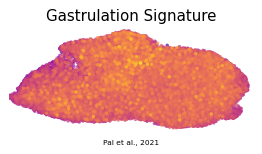

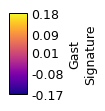

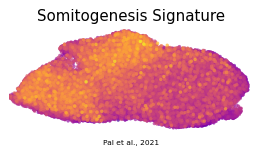

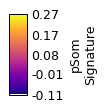

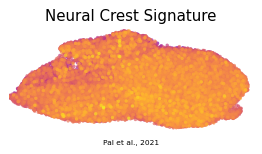

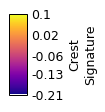

In [8]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Pal et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [9]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (59359, 26383)
